In [1]:
#initiating library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv('data/train.csv')

df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
print(df.shape)
df.info()

(1460, 81)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 1

## Deteksi Missing Value

In [4]:
missing = df.isnull().sum()
print(missing[missing > 0])



LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64


In [5]:
df = df.loc[:, df.isnull().mean() <= 0.5]

In [6]:
missing = (df.isnull().mean() * 100).sort_values(ascending=False)
print(missing[missing > 0])


FireplaceQu     47.260274
LotFrontage     17.739726
GarageYrBlt      5.547945
GarageQual       5.547945
GarageFinish     5.547945
GarageType       5.547945
GarageCond       5.547945
BsmtFinType2     2.602740
BsmtExposure     2.602740
BsmtQual         2.534247
BsmtCond         2.534247
BsmtFinType1     2.534247
MasVnrArea       0.547945
Electrical       0.068493
dtype: float64


kolom Alley, MasVnrType, FireplaceQu, PoolQC, Fence, MiscFeature dihapus karena data kosong lebih dari 50%, dan dibawah, kolom yang memiliki missing value dibawah 50% akan di imputasi

dan sebenernya fitur PoolQC, Fence, Alley seharusnya tidak di buang, karena sesuai deskripsi data, fitur ini kosong karena rumah tersebut memang tidak memiliki fitur itu. namun karena intruksi ingin data kosong diatas 50% dihapus, jadi saya tetap menghapusnya

In [7]:
df = df.drop(columns=['Id'])

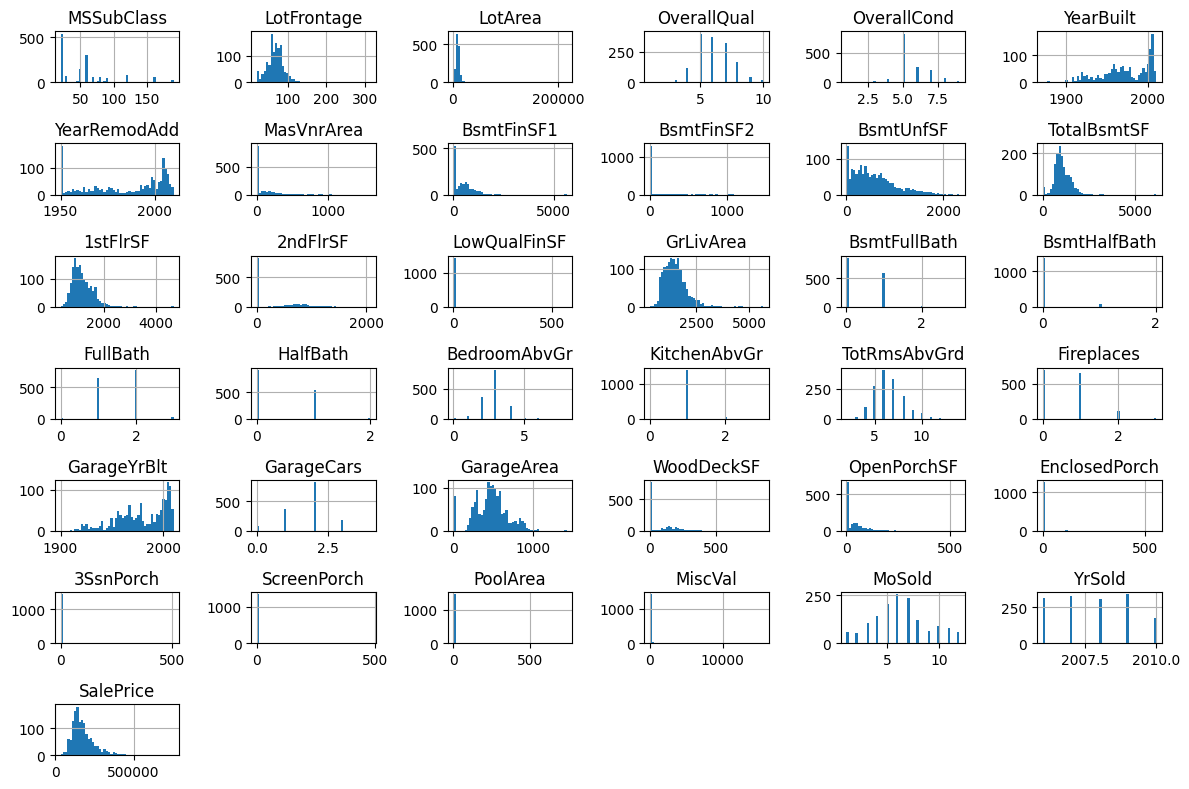

In [8]:
df_num = df.select_dtypes(include=['number'])

df_num.hist(figsize=(12, 8), bins=50)
plt.tight_layout()
plt.show()

In [9]:
missing_cols = df.columns[df.isna().mean() > 0]
missing_cols

Index(['LotFrontage', 'MasVnrArea', 'BsmtQual', 'BsmtCond', 'BsmtExposure',
       'BsmtFinType1', 'BsmtFinType2', 'Electrical', 'FireplaceQu',
       'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageQual',
       'GarageCond'],
      dtype='object')

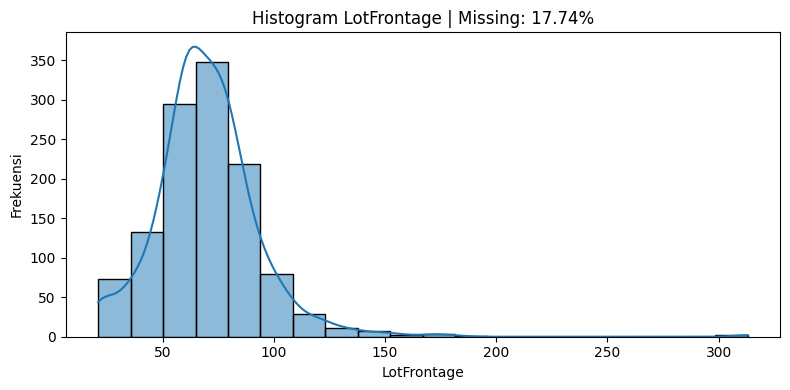

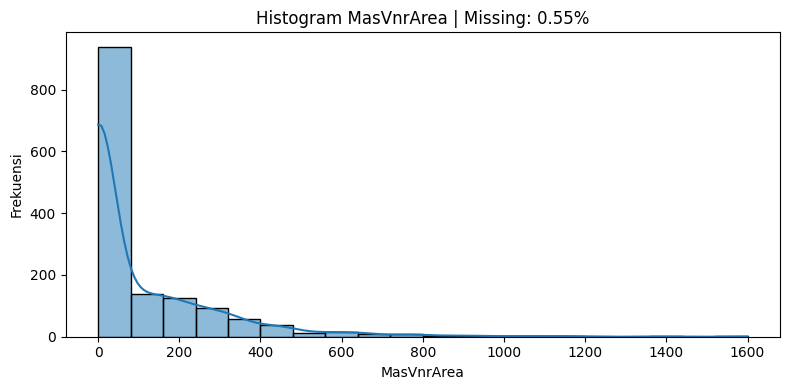

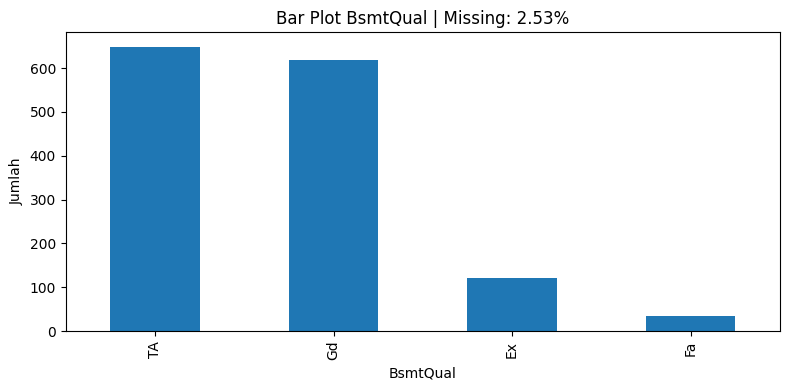

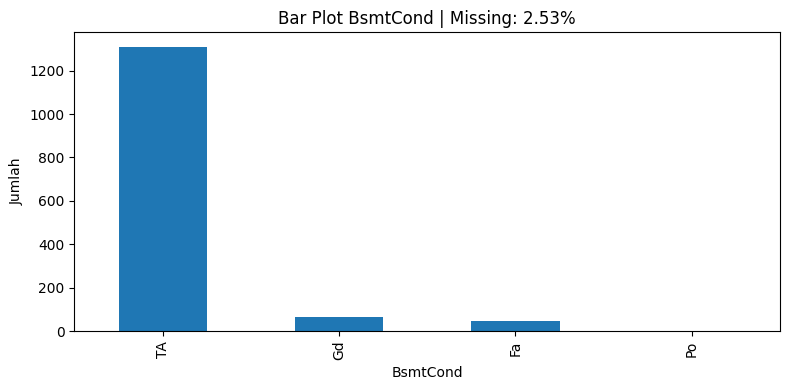

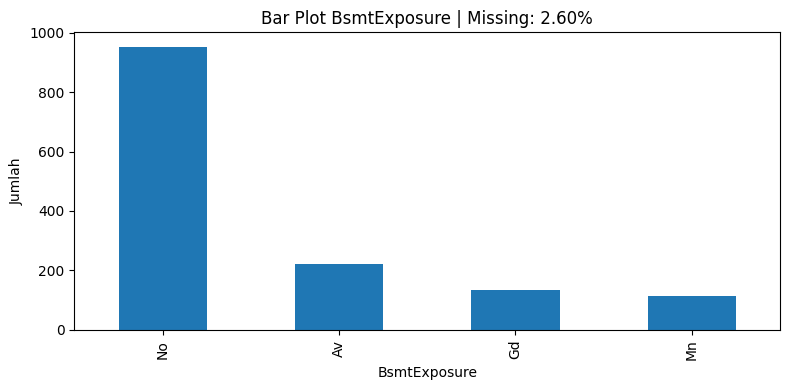

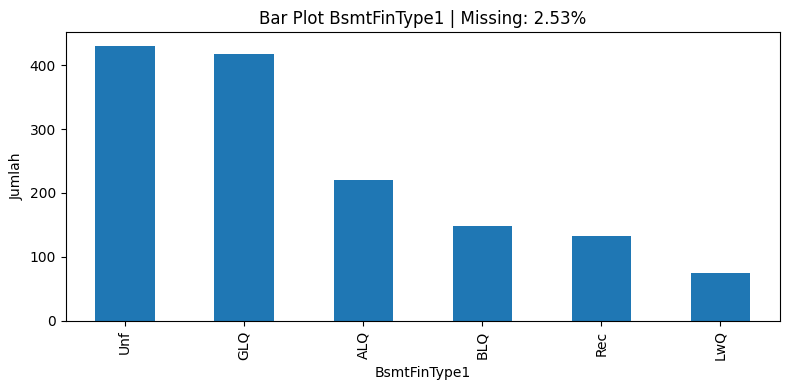

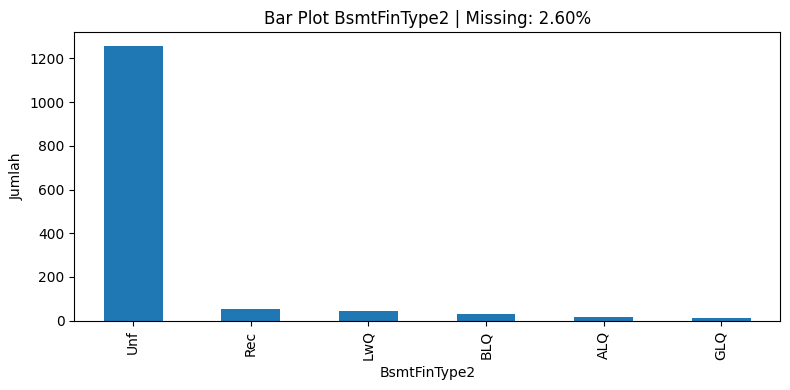

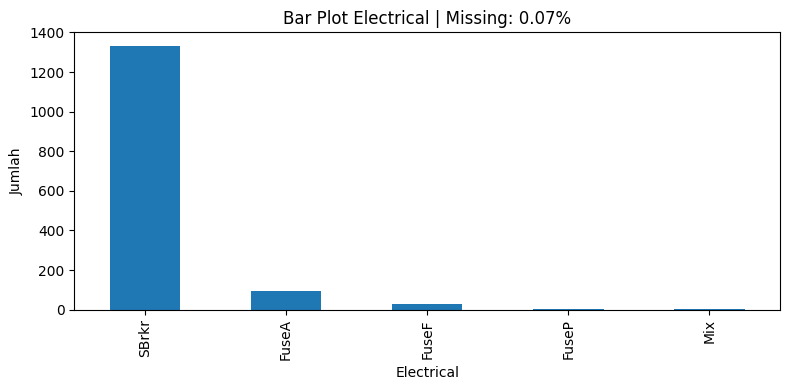

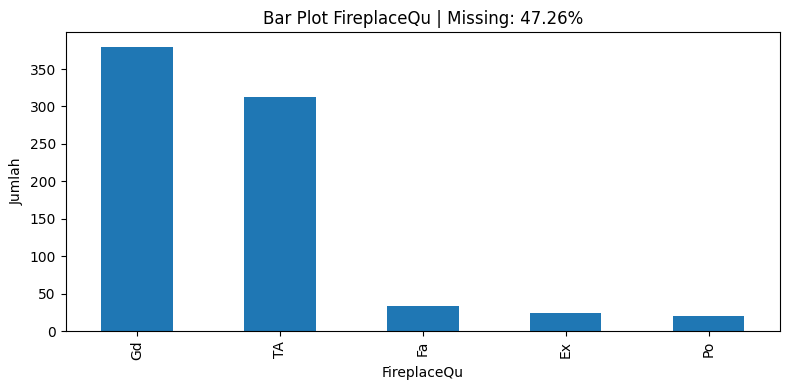

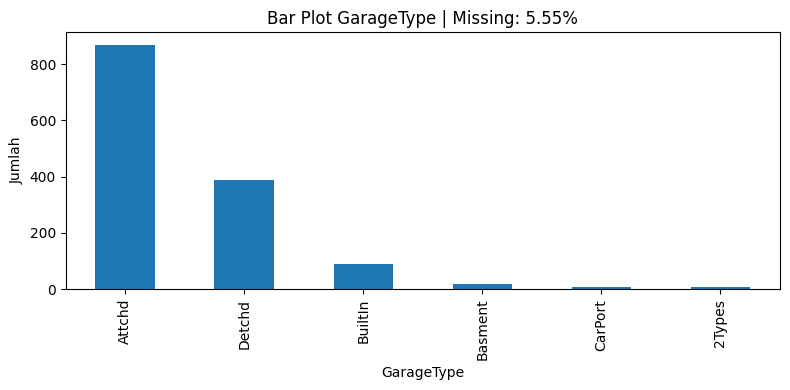

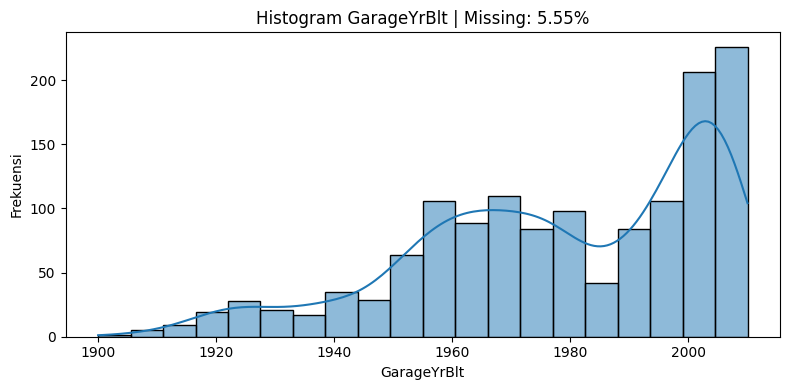

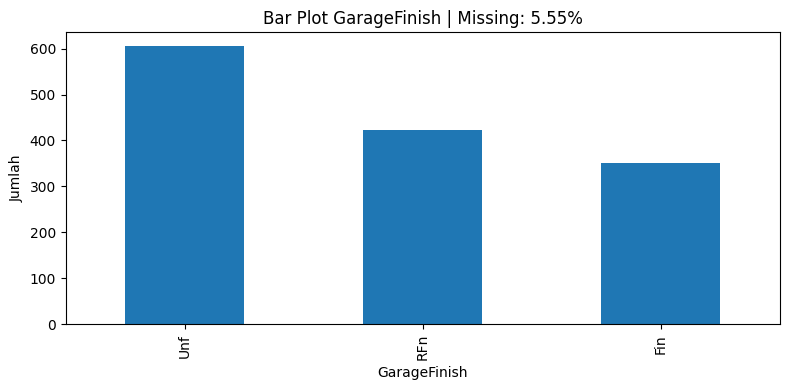

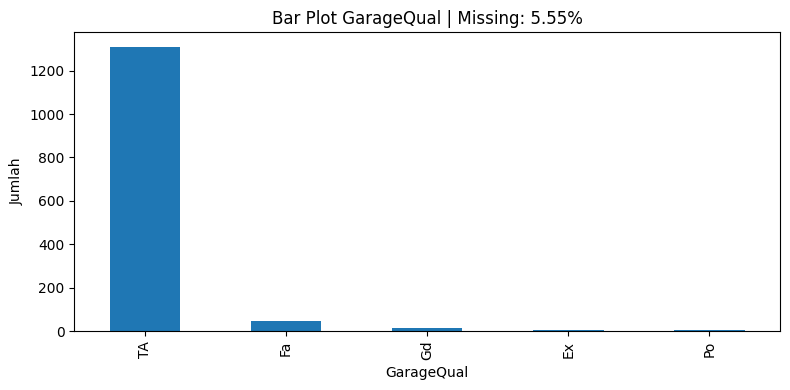

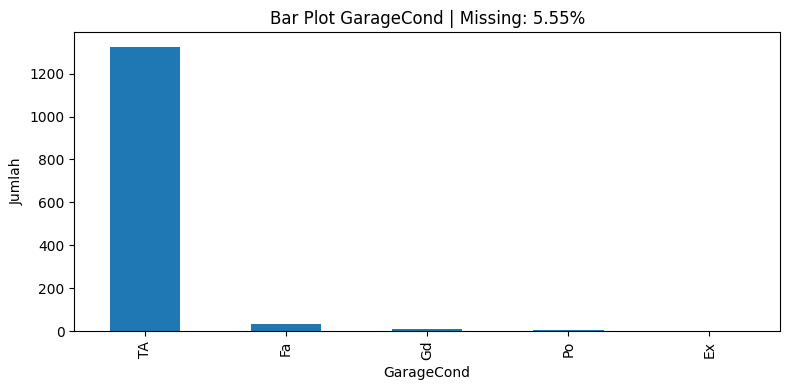

In [10]:
for col in missing_cols:
    if df[col].dtype in ['int64', 'float64']:
        plt.figure(figsize=(8, 4))
        sns.histplot(df[col].dropna(), bins=20, kde=True)
        plt.title(f'Histogram {col} | Missing: {df[col].isna().mean()*100:.2f}%')
        plt.xlabel(col)
        plt.ylabel('Frekuensi')
        plt.tight_layout()
        plt.show()
    else:
        plt.figure(figsize=(8, 4))
        df[col].value_counts().plot(kind='bar')
        plt.title(f'Bar Plot {col} | Missing: {df[col].isna().mean()*100:.2f}%')
        plt.xlabel(col)
        plt.ylabel('Jumlah')
        plt.tight_layout()
        plt.show()

dari yang kita bisa lihat, data ini memiliki banyak missing value di data kategorikal, yang artinya missing value disini itu karena emang rumahnya nggak punya fitur tersebut

In [11]:
# 1. Imputasi numerik
# LotFrontage: median per neighborhood
df['LotFrontage'] = df.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median())
)
# MasVnrArea: jika tidak ada veneer, biasanya 0
df['MasVnrArea'] = df['MasVnrArea'].fillna(0)

# GarageYrBlt: jika tidak ada data garasi, pakai tahun bangunan rumah
df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['YearBuilt'])

# 2. Imputasi kategori yang berarti "tidak ada"
basement_cols = [
    'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2'
]
for col in basement_cols:
    df[col] = df[col].fillna('NoBasement')

garage_cols = [
    'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond'
]
for col in garage_cols:
    df[col] = df[col].fillna('NoGarage')

df['FireplaceQu'] = df['FireplaceQu'].fillna('NoFireplace')

# 3. Imputasi sisa data yang sedikit missing
df['Electrical'] = df['Electrical'].fillna(df['Electrical'].mode()[0])



In [12]:
new_missing =( df.isnull().mean() * 100).sort_values(ascending=False)
print(new_missing[new_missing > 0])

Series([], dtype: float64)


sudah tidak ada missing value

## Deteksi Outlier


In [13]:
num_col = df.select_dtypes(include=['number'])

outlier_data = []

for col in num_col:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR =   Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier = df[(df[col] < lower) | (df[col] > upper)]

    if not outlier.empty:
        print(f"{col} : {len(outlier)}  outlier")
        outlier_data.append(col)


MSSubClass : 103  outlier
LotFrontage : 93  outlier
LotArea : 69  outlier
OverallQual : 2  outlier
OverallCond : 125  outlier
YearBuilt : 7  outlier
MasVnrArea : 98  outlier
BsmtFinSF1 : 7  outlier
BsmtFinSF2 : 167  outlier
BsmtUnfSF : 29  outlier
TotalBsmtSF : 61  outlier
1stFlrSF : 20  outlier
2ndFlrSF : 2  outlier
LowQualFinSF : 26  outlier
GrLivArea : 31  outlier
BsmtFullBath : 1  outlier
BsmtHalfBath : 82  outlier
BedroomAbvGr : 35  outlier
KitchenAbvGr : 68  outlier
TotRmsAbvGrd : 30  outlier
Fireplaces : 5  outlier
GarageYrBlt : 2  outlier
GarageCars : 5  outlier
GarageArea : 21  outlier
WoodDeckSF : 32  outlier
OpenPorchSF : 77  outlier
EnclosedPorch : 208  outlier
3SsnPorch : 24  outlier
ScreenPorch : 116  outlier
PoolArea : 7  outlier
MiscVal : 52  outlier
SalePrice : 61  outlier


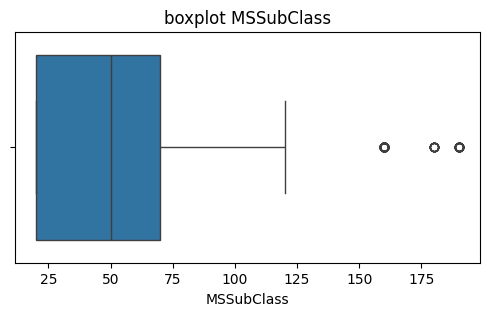

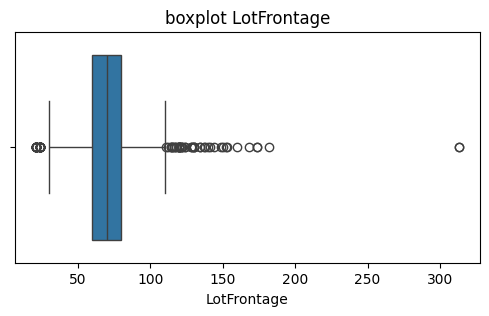

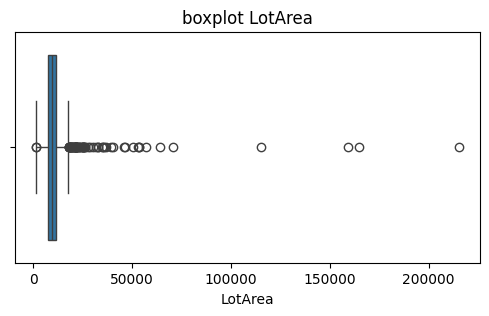

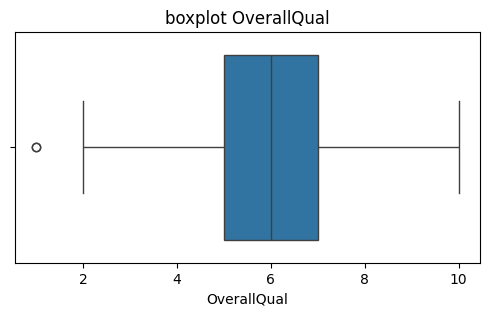

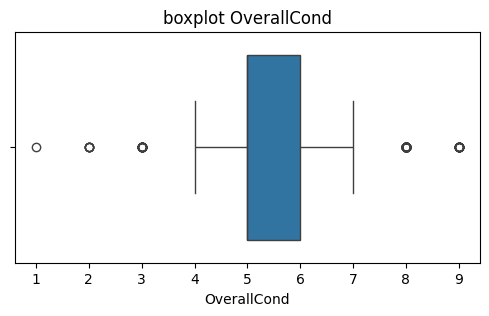

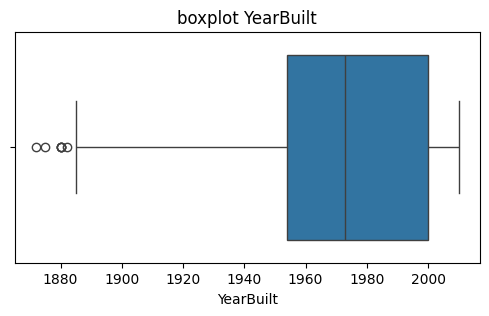

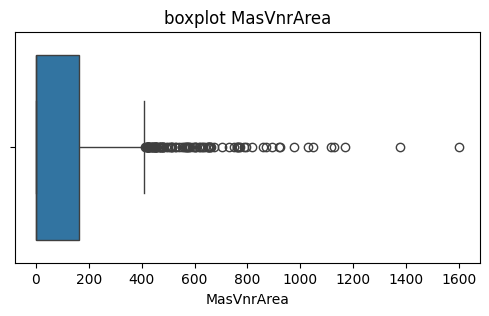

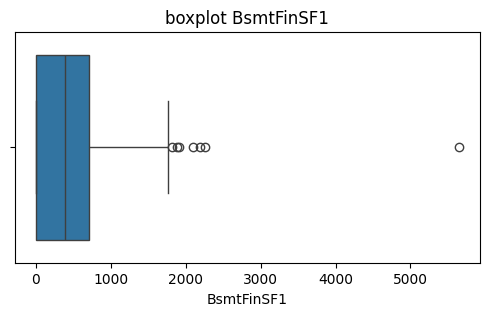

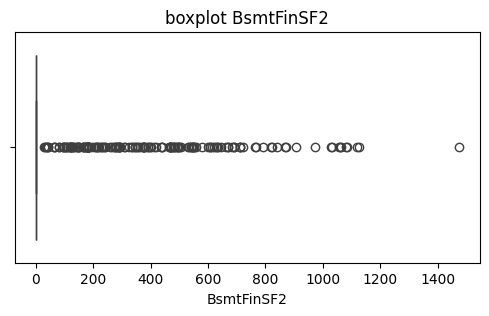

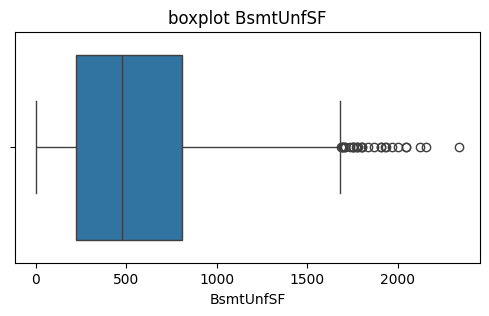

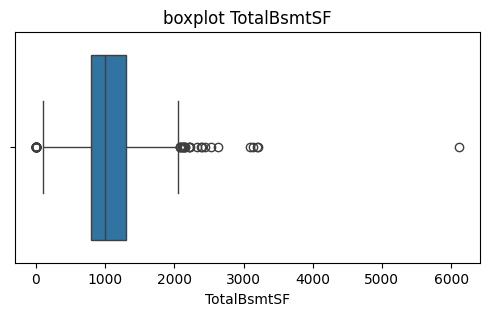

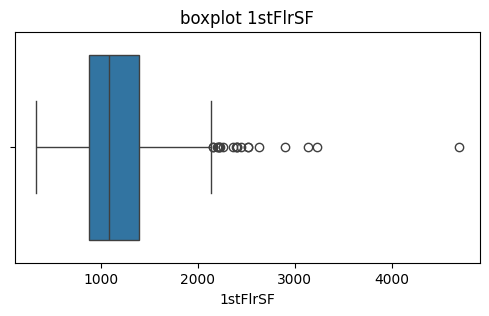

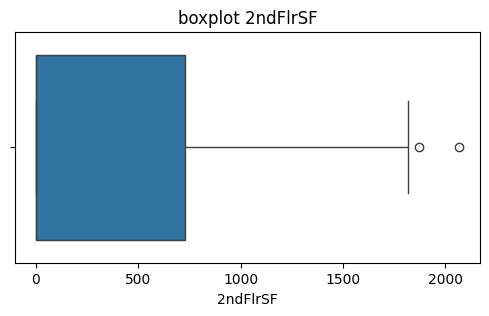

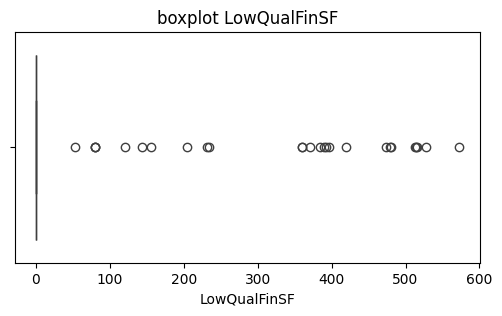

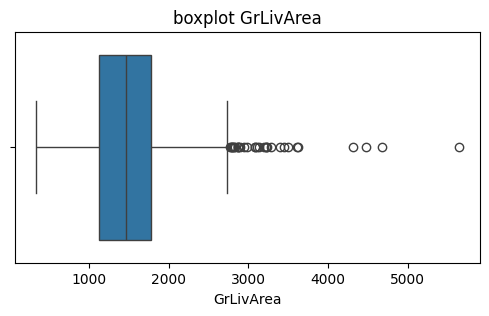

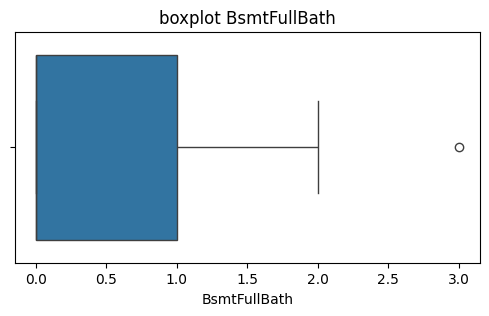

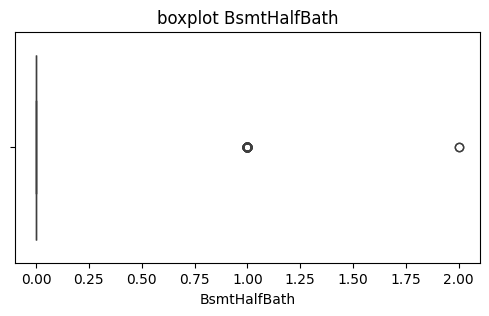

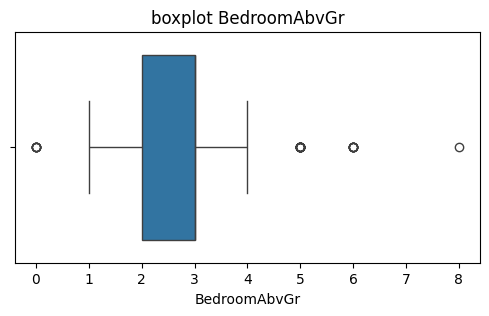

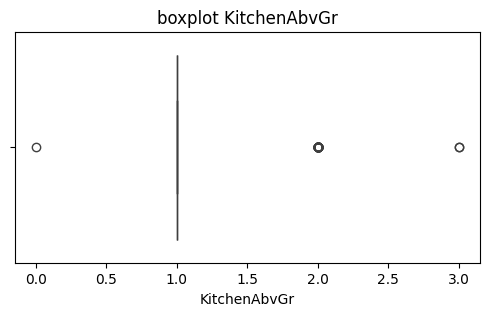

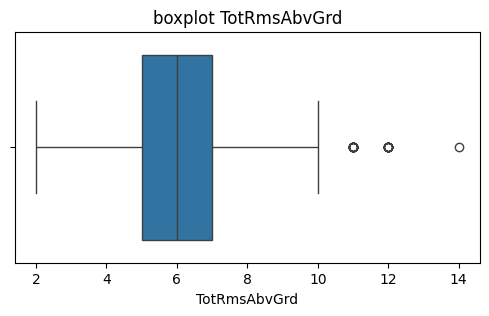

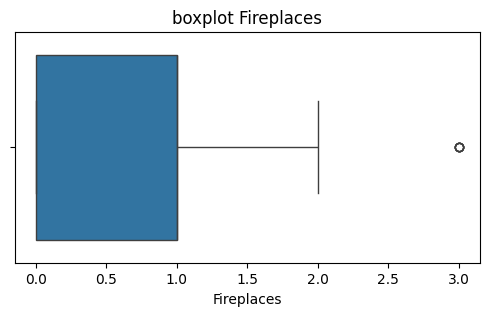

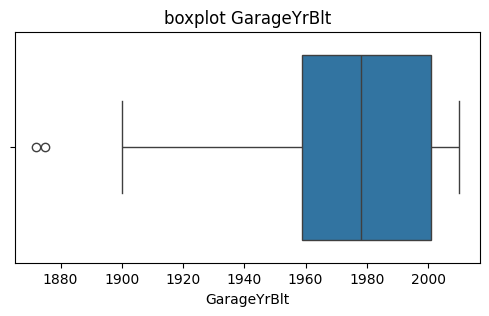

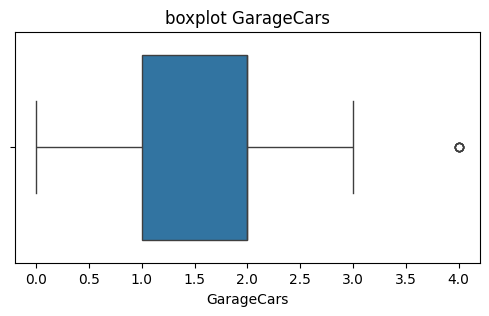

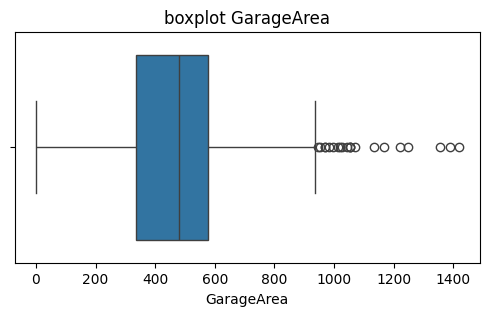

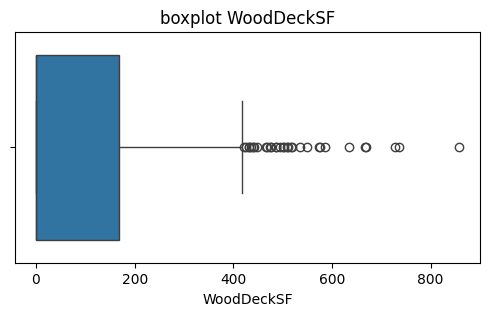

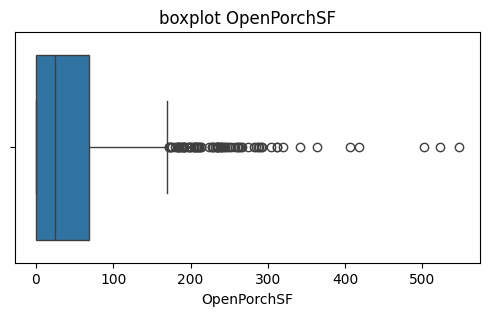

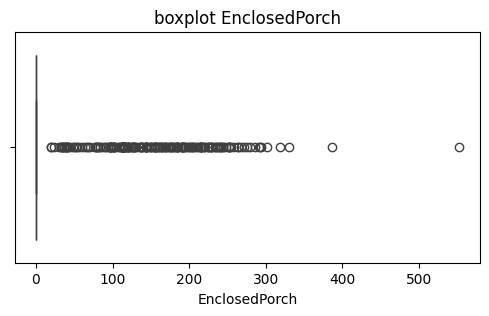

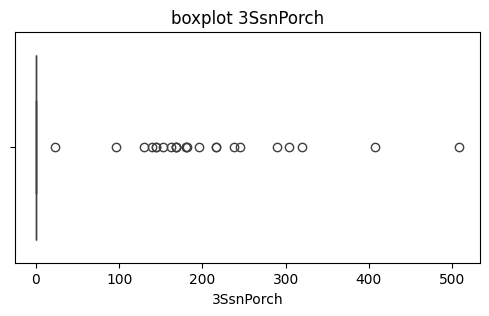

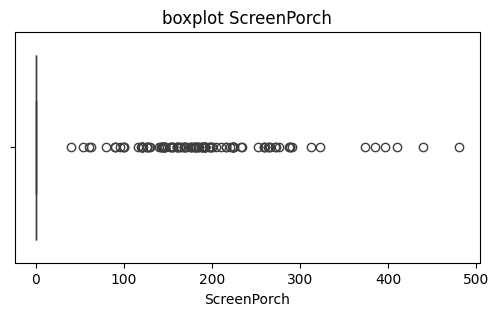

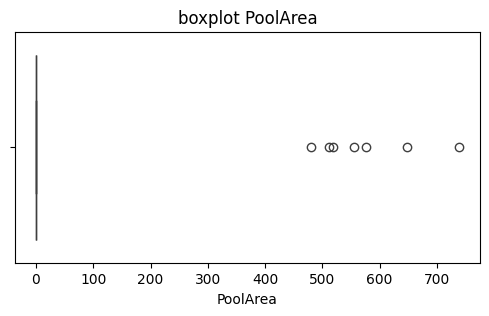

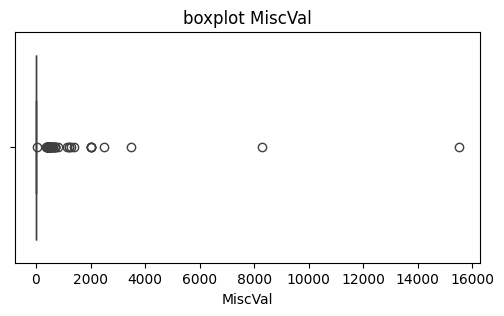

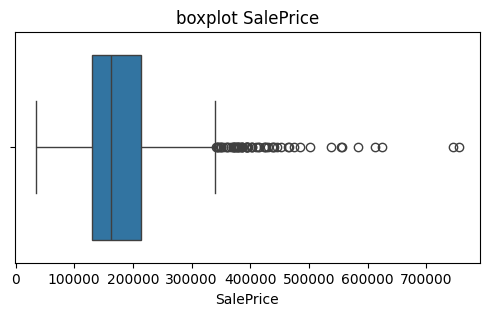

In [14]:
for col in outlier_data:
    plt.figure(figsize=(6,3))
    sns.boxplot(x=df[col])
    plt.title(f'boxplot {col}')
    plt.show()

In [15]:
# contoh untuk kolom tertentu
for col in outlier_data:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    print(col)
    print(df[(df[col] < lower) | (df[col] > upper)][[col]].head())

MSSubClass
    MSSubClass
9          190
48         190
56         160
75         180
87         160
LotFrontage
    LotFrontage
36        112.0
41        115.0
56         24.0
75         21.0
85        121.0
LotArea
     LotArea
53     50271
66     19900
113    21000
120    21453
159    19378
OverallQual
     OverallQual
375            1
533            1
OverallCond
    OverallCond
1             8
15            8
24            8
88            2
91            3
YearBuilt
      YearBuilt
304        1880
630        1880
747        1880
991        1882
1132       1880
MasVnrArea
    MasVnrArea
25       640.0
37       650.0
45       412.0
56       456.0
58      1031.0
BsmtFinSF1
     BsmtFinSF1
53         1810
70         1880
178        1904
523        2260
898        2188
BsmtFinSF2
    BsmtFinSF2
7           32
24         668
26         486
42          93
43         491
BsmtUnfSF
     BsmtUnfSF
22        1777
78        1768
137       1907
169       1686
224       2336
TotalBsmtSF
     To

In [16]:
df['HasPool'] = (df['PoolArea'] > 0).astype(int)
df['HasScreenPorch'] = (df['ScreenPorch'] > 0).astype(int)
df['HasEnclosedPorch'] = (df['EnclosedPorch'] > 0).astype(int)

Outlier yang terdeteksi tidak langsung dihapus. Sebagian besar outlier pada fitur numerik seperti LotArea, LotFrontage, SalePrice, GarageArea, dan area tambahan dianggap valid karena mencerminkan rumah dengan ukuran atau fasilitas yang jauh lebih besar dari rata-rata. Oleh karena itu, outlier hanya disesuaikan jika nilai yang ekstrem tersebut tidak masuk akal secara domain, misalnya data error atau nilai absurd. Untuk fitur dengan distribusi sangat skewed dan banyak nilai 0 seperti EnclosedPorch, ScreenPorch, dan PoolArea, lebih tepat dibuat variabel biner atau dipertahankan karena data tersebut mencerminkan keberadaan fitur tertentu.

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 78 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   MSSubClass        1460 non-null   int64  
 1   MSZoning          1460 non-null   object 
 2   LotFrontage       1460 non-null   float64
 3   LotArea           1460 non-null   int64  
 4   Street            1460 non-null   object 
 5   LotShape          1460 non-null   object 
 6   LandContour       1460 non-null   object 
 7   Utilities         1460 non-null   object 
 8   LotConfig         1460 non-null   object 
 9   LandSlope         1460 non-null   object 
 10  Neighborhood      1460 non-null   object 
 11  Condition1        1460 non-null   object 
 12  Condition2        1460 non-null   object 
 13  BldgType          1460 non-null   object 
 14  HouseStyle        1460 non-null   object 
 15  OverallQual       1460 non-null   int64  
 16  OverallCond       1460 non-null   int64  


## Transformasi data


In [18]:
X = df.drop(columns=['SalePrice'])
y = df['SalePrice']


In [19]:
skew = X.select_dtypes(include = ['number']).skew().sort_values(ascending=False)
print(skew[skew > 1])

log_features = [
    'MiscVal', 'LotArea', '3SsnPorch', 'LowQualFinSF',
    'BsmtFinSF2', 'ScreenPorch', 'EnclosedPorch', 'MasVnrArea',
    'OpenPorchSF', 'LotFrontage', 'BsmtFinSF1', 'WoodDeckSF', 
     '1stFlrSF', 'GrLivArea', '2ndFlrSF'
]

skew_before = X[log_features].skew()
X[log_features] = np.log1p(X[log_features])
skew_after = X[log_features].skew()

pd.DataFrame({'sebelum': skew_before, 'sesudah': skew_after}).round(2)


MiscVal             24.476794
PoolArea            14.828374
HasPool             14.352680
LotArea             12.207688
3SsnPorch           10.304342
LowQualFinSF         9.011341
KitchenAbvGr         4.488397
BsmtFinSF2           4.255261
ScreenPorch          4.122214
BsmtHalfBath         4.103403
HasScreenPorch       3.113266
EnclosedPorch        3.089872
MasVnrArea           2.677616
OpenPorchSF          2.364342
LotFrontage          2.212959
HasEnclosedPorch     2.047921
BsmtFinSF1           1.685503
WoodDeckSF           1.541376
TotalBsmtSF          1.524255
MSSubClass           1.407657
1stFlrSF             1.376757
GrLivArea            1.366560
dtype: float64


,sebelum,sesudah
MiscVal,24.48,5.17
LotArea,12.21,-0.14
3SsnPorch,10.30,7.73
LowQualFinSF,9.01,7.46
BsmtFinSF2,4.26,2.52
ScreenPorch,4.12,3.15
EnclosedPorch,3.09,2.11
MasVnrArea,2.68,0.50
OpenPorchSF,2.36,-0.02
LotFrontage,2.21,-0.91


In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder



In [21]:

nominal_col = ['MSZoning', 'Street', 'LandContour', 'LotConfig', 'Neighborhood', 
                'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 
                'RoofMatl', 'Exterior1st', 'Exterior2nd', 'Foundation', 'Heating', 
                'CentralAir', 'GarageType', 'SaleType', 'SaleCondition']

if 'MSSubClass' in df.columns:
    df['MSSubClass'] = df['MSSubClass'].astype(str)
    nominal_col.append('MSSubClass')

ordinal_col = ['LotShape', 'Utilities', 'LandSlope', 'ExterQual', 'ExterCond', 
                'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 
                'HeatingQC', 'Electrical', 'KitchenQual', 'Functional', 'GarageFinish', 
                'GarageQual', 'GarageCond', 'PavedDrive', 'FireplaceQu']


numerical_col = [col for col in df.select_dtypes(include=["number"]).columns if col not in nominal_col + ordinal_col + ['SalePrice', 'Id']]

nominal_col = [col for col in nominal_col if col in df.columns]
ordinal_col = [col for col in ordinal_col if col in df.columns]
numerical_col = [col for col in numerical_col if col in df.columns]

print(f"Jumlah nominal: {len(nominal_col)}")
print(f"Jumlah ordinal: {len(ordinal_col)}")
print(f"Jumlah numerik: {len(numerical_col)}")



Jumlah nominal: 20
Jumlah ordinal: 19
Jumlah numerik: 38


In [22]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_col),             
        ('ord', OrdinalEncoder(), ordinal_col),               
        ('nom', OneHotEncoder(handle_unknown='ignore', sparse_output=False), nominal_col) 
    ],
    remainder='passthrough' 
)


In [23]:
df_transformed = preprocessor.fit_transform(df)

nom_feature_names = preprocessor.named_transformers_['nom'].get_feature_names_out(nominal_col)

all_feature_names = numerical_col + ordinal_col + list(nom_feature_names)


if 'SalePrice' in df.columns:
    all_feature_names.append('SalePrice')

df_final = pd.DataFrame(df_transformed, columns=all_feature_names, index=df.index)

df_final.head()

,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,...,MSSubClass_40,MSSubClass_45,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90,SalePrice
0,-0.231877,-0.207142,0.651479,-0.517200,1.050994,0.878668,0.514104,0.575425,-0.288653,-0.944591,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,208500.0
1,0.437043,-0.091886,-0.071836,2.179628,0.156734,-0.429577,-0.570750,1.171992,-0.288653,-0.641228,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,181500.0
2,-0.098093,0.073480,0.651479,-0.517200,0.984752,0.830215,0.325915,0.092907,-0.288653,-0.301643,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,223500.0
3,-0.454850,-0.096897,0.651479,-0.517200,-1.863632,-0.720298,-0.570750,-0.499274,-0.288653,-0.061670,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,140000.0
4,0.615421,0.375148,1.374795,-0.517200,0.951632,0.733308,1.366489,0.463568,-0.288653,-0.174865,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,250000.0


## Reduksi Data

In [ ]:

corr_matrix = df_final.corr().abs()


upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

high_corr_pairs = (
    upper.stack()
    .reset_index()
    .rename(columns={'level_0': 'Fitur A', 'level_1': 'Fitur B', 0: 'Korelasi'})
    .query('Korelasi >= 0.85')
    .sort_values('Korelasi', ascending=False)
    .reset_index(drop=True)
)

print(f"Total pasangan fitur dengan korelasi >= 85%: {len(high_corr_pairs)}")
high_corr_pairs['Korelasi'] = high_corr_pairs['Korelasi'].round(4)
high_corr_pairs

Total pasangan fitur dengan korelasi >= 85%: 20


,Fitur A,Fitur B,Korelasi
0,Street_Grvl,Street_Pave,1.0000
1,Exterior1st_CBlock,Exterior2nd_CBlock,1.0000
2,BldgType_Duplex,MSSubClass_90,1.0000
3,CentralAir_N,CentralAir_Y,1.0000
4,PoolArea,HasPool,0.9897
5,SaleType_New,SaleCondition_Partial,0.9868
6,BldgType_2fmCon,MSSubClass_190,0.9834
7,Exterior1st_VinylSd,Exterior2nd_VinylSd,0.9775
8,Exterior1st_CemntBd,Exterior2nd_CmentBd,0.9742
9,Exterior1st_MetalSd,Exterior2nd_MetalSd,0.9731


In [25]:
from sklearn.decomposition import PCA

corr_matrix = df_final.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

to_drop = [column for column in upper.columns if any(upper[column] > 0.85)]
print(f"kolom dengan korelasi tinnggi: {to_drop}")

df_final = df_final.drop(columns=to_drop)

kolom dengan korelasi tinnggi: ['GarageArea', 'HasPool', 'HasScreenPorch', 'HasEnclosedPorch', 'Street_Pave', 'Neighborhood_Somerst', 'RoofStyle_Hip', 'Exterior2nd_CBlock', 'Exterior2nd_CmentBd', 'Exterior2nd_HdBoard', 'Exterior2nd_MetalSd', 'Exterior2nd_VinylSd', 'Exterior2nd_Wd Sdng', 'CentralAir_Y', 'SaleCondition_Partial', 'MSSubClass_190', 'MSSubClass_45', 'MSSubClass_50', 'MSSubClass_80', 'MSSubClass_90']


PCA
    

In [26]:

X_final = df_final.drop(columns=['SalePrice'])
y_final = df_final['SalePrice']

pca = PCA(n_components=0.95, random_state=42)
X_pca = pca.fit_transform(X_final)

print(f"Jumlah kolom fitur sebelum PCA: {X_final.shape[1]}")
print(f"Jumlah kolom fitur setelah PCA: {X_pca.shape[1]}")

df_final = pd.DataFrame(X_pca, columns=[f'PC{i+1}' for i in range(X_pca.shape[1])], index=df_final.index)

df_final['SalePrice'] = y_final
df_final    .head()

Jumlah kolom fitur sebelum PCA: 204
Jumlah kolom fitur setelah PCA: 54


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC46,PC47,PC48,PC49,PC50,PC51,PC52,PC53,PC54,SalePrice
0,-2.362360,-0.317987,-0.631844,-3.133173,-0.650565,0.587876,1.420894,0.093749,0.248830,0.476001,...,-0.322159,0.726774,-0.113885,0.154744,0.005902,-0.285525,0.022687,-0.056448,0.027735,208500.0
1,-0.917558,-3.466428,-0.381003,-0.526198,-0.959251,-0.209866,-0.481599,1.919526,0.166300,0.200826,...,0.304132,-0.363036,0.579563,0.487196,-0.260895,-0.514686,-0.240028,-0.498768,-0.679628,181500.0
2,-2.964508,-0.519175,-0.137577,-2.689773,1.059490,-0.481081,-1.181974,-0.264749,0.831066,0.574502,...,0.172826,0.371679,0.253647,0.232377,0.089763,-0.170612,0.104533,0.036627,-0.159578,223500.0
3,0.978043,-2.031713,1.639035,-1.045283,-1.378010,-0.028273,-1.548755,0.055454,0.344176,-2.039430,...,-0.648497,0.167494,-0.512435,-0.079276,0.191489,0.784377,-0.342587,0.315277,1.000876,140000.0
4,-4.964725,-0.343195,1.834210,-1.994021,0.826029,-0.146257,-1.111084,-0.272303,0.130311,-0.090658,...,-0.144931,0.165980,0.227138,0.052725,0.017601,-0.066234,0.214072,-0.149910,-0.173554,250000.0


In [27]:

df_final.to_csv('5054251032_Rasya_Tugas_Praproses_Data.csv', index=False)